<a href="https://colab.research.google.com/github/SinhaPushkar047/Langgraph/blob/main/UPSC_Essay_Evaluator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [209]:
from langgraph.graph import StateGraph,START,END
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from typing import TypedDict,Annotated
from pydantic import BaseModel,Field
import operator

In [210]:
from google.colab import userdata
groq_api=userdata.get('GROQ_API_KEY')

In [211]:
model=ChatGroq(
    model='openai/gpt-oss-120b',
    api_key=groq_api
)

In [212]:
class EvaluationSchema(BaseModel):

  feedback: str=Field(description='Detailed feedback for the eassy')
  score: int=Field(description='Score out of 10 in integer',ge=0,le=10)

In [213]:
struc_model=model.with_structured_output(EvaluationSchema)

In [214]:
essay="""Role of India in AI at the Global Level
Introduction
Artificial Intelligence (AI) is one of the most important technologies of the 21st century. It is transforming industries such as healthcare, education, agriculture, defence, transportation, and manufacturing. Countries across the world are investing heavily in AI to strengthen their economies and improve the quality of life of their citizens. India, with its large population, strong IT industry, skilled workforce, and growing startup ecosystem, is emerging as an important player in the global AI revolution.
India's Growing Importance in AI
India has established itself as a major centre for information technology and software development. Its large pool of engineers, researchers, and technology professionals provides a strong foundation for AI development. Indian companies are developing AI-powered applications, chatbots, automation tools, and data-driven solutions for businesses worldwide.
India is also promoting AI research and innovation through government initiatives, educational institutions, and private companies. The IndiaAI Mission aims to strengthen the country's AI infrastructure, support startups, improve access to computing resources, and develop AI skills among its citizens. These efforts can help India become a global hub for responsible and affordable AI solutions.
India's Contribution to the Global Economy
AI is creating new opportunities for economic growth, and India has the potential to contribute significantly to this transformation. Indian IT companies provide AI services to international clients, helping businesses improve efficiency, reduce costs, and make better decisions. Indian startups are also using AI to solve real-world problems in finance, healthcare, education, and logistics.
Furthermore, AI can generate employment opportunities in software development, machine learning, data science, robotics, and research. Although automation may affect some traditional jobs, India can benefit by investing in reskilling and preparing its workforce for emerging careers.
Applications of AI in Important Sectors
India's role in AI extends beyond the technology industry. In healthcare, AI can assist doctors in analysing medical images, identifying diseases, and improving access to healthcare in rural areas. In agriculture, AI-based systems can help farmers predict weather conditions, identify crop diseases, and use water and fertilisers more efficiently.
In education, AI-powered tools can provide personalised learning experiences and support students in different languages. AI can also improve public services, disaster management, transportation, and environmental monitoring. By developing solutions for its own challenges, India can create technologies that are useful for other developing countries as well.
India's Role in Global AI Cooperation
India can play an important role in shaping international AI policies and standards. Its participation in global discussions on AI governance, safety, ethics, and digital inclusion allows it to represent the interests of developing nations.
India hosted the Global Partnership on Artificial Intelligence (GPAI) summit in 2023 and hosted the AI Impact Summit in New Delhi in February 2026, strengthening its position in international AI discussions. India can collaborate with countries such as the United States, Japan, France, and other technology leaders to promote research, share knowledge, and establish responsible AI practices.
India can also contribute to making AI more accessible to countries with limited resources. Developing affordable AI tools and supporting multilingual technologies can help reduce the global digital divide.
Challenges Faced by India
Despite its progress, India faces several challenges in becoming a leading AI power. These include limited access to advanced computing infrastructure, the need for greater investment in research and development, a shortage of specialised AI professionals, and concerns about data privacy and security.
Another major challenge is ensuring that the benefits of AI reach all sections of society. AI systems must be fair, transparent, and accessible to people from different economic and linguistic backgrounds. India must also address the possible displacement of workers through education, training, and employment policies.
To overcome these challenges, the country needs stronger cooperation between the government, universities, research institutions, and private companies. Increased investment in indigenous AI models, semiconductor technology, and high-quality datasets will also be essential.
Conclusion
India has the potential to become one of the leading countries in the global AI ecosystem. Its technological expertise, young workforce, entrepreneurial spirit, and commitment to digital development provide a strong foundation for future growth. However, achieving global leadership will require sustained investment in research, infrastructure, education, and ethical AI development.
India's goal should not be limited to adopting technologies developed by other countries. It should also focus on creating innovative AI systems that address local and global challenges. By promoting responsible innovation, international cooperation, and inclusive growth, India can play a significant role in shaping the future of artificial intelligence and contribute to a more prosperous and technologically advanced world."""

In [218]:
class UPSCState(TypedDict):
  essay: str
  language_feedback: str
  analysis_feedback: str
  clarity_feedback: str
  overall_feedback: str
  individual_score: Annotated[list[int],operator.add]
  avg_score: float

In [219]:
def eval_lang(state: UPSCState)->UPSCState:
  prompt = f'Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'

  output=struc_model.invoke(prompt)

  return {'language_feedback':output.feedback,'individual_score':[output.score]}

In [220]:
def eval_anal(state:UPSCState)->UPSCState:
  prompt = f'Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'

  output=struc_model.invoke(prompt)

  return{'analysis_feedback':output.feedback,'individual_score':[output.score]}

In [221]:
def eval_thought(state:UPSCState)->UPSCState:
  prompt = f'Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 \n {state["essay"]}'

  output=struc_model.invoke(prompt)

  return{'clarity_feedback':output.feedback,'individual_score':[output.score]}

In [222]:
def eval_final(state:UPSCState)->UPSCState:
  prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity of thought feedback - {state["clarity_feedback"]}'

  output=model.invoke(prompt).content

  avg_score=sum(state['individual_score'])/len(state['individual_score'])

  return{'overall_feedback':output,'avg_score':avg_score}

In [223]:
graph=StateGraph(UPSCState)

graph.add_node('evaluate_language',eval_lang)
graph.add_node('evaluate_analysis',eval_anal)
graph.add_node('evaluate_thought',eval_thought)
graph.add_node('final_evaluate',eval_final)

graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_thought')

graph.add_edge('evaluate_language','final_evaluate')
graph.add_edge('evaluate_analysis','final_evaluate')
graph.add_edge('evaluate_thought','final_evaluate')

graph.add_edge('final_evaluate',END)

workflow=graph.compile()

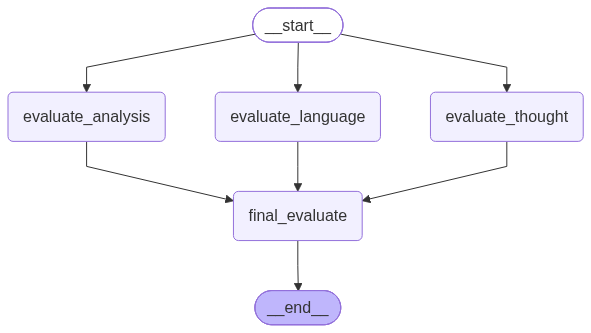

In [224]:
workflow

In [225]:
initial_state={'essay':essay}

final_state=workflow.invoke(initial_state)

In [228]:
final_state

{'essay': "Role of India in AI at the Global Level\nIntroduction\nArtificial Intelligence (AI) is one of the most important technologies of the 21st century. It is transforming industries such as healthcare, education, agriculture, defence, transportation, and manufacturing. Countries across the world are investing heavily in AI to strengthen their economies and improve the quality of life of their citizens. India, with its large population, strong IT industry, skilled workforce, and growing startup ecosystem, is emerging as an important player in the global AI revolution.\nIndia's Growing Importance in AI\nIndia has established itself as a major centre for information technology and software development. Its large pool of engineers, researchers, and technology professionals provides a strong foundation for AI development. Indian companies are developing AI-powered applications, chatbots, automation tools, and data-driven solutions for businesses worldwide.\nIndia is also promoting AI 